In [1]:
import os, glob, shutil, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def chuan_bi_du_lieu():
    """Nếu chưa có thư mục data/ thì cho tải lên: một tệp .zip chứa data, hoặc các tệp .csv."""
    if glob.glob("data/*.csv"):
        print("Đã có thư mục data/:", sorted(os.listdir("data")))
        return
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Không thấy data/*.csv, hãy đặt thư mục data cạnh notebook.")
    print("Chọn tệp .zip của thư mục data, hoặc chọn cùng lúc các tệp .csv")
    up = files.upload()
    os.makedirs("data", exist_ok=True)
    for ten in list(up):
        if ten.lower().endswith(".zip"):
            zipfile.ZipFile(ten).extractall("_tmp_zip")
        elif ten.lower().endswith(".csv"):
            shutil.move(ten, os.path.join("data", ten))
    for f in glob.glob("_tmp_zip/**/*.csv", recursive=True):
        shutil.copy(f, "data/")
    print("Các tệp trong data/:", sorted(os.listdir("data")))

# Cách khác: dữ liệu để trên Google Drive
# from google.colab import drive; drive.mount("/content/drive"); os.chdir("/content/drive/MyDrive/MayHoc/bai07_danh_gia")
chuan_bi_du_lieu()

Chọn tệp .zip của thư mục data, hoặc chọn cùng lúc các tệp .csv


Saving gia_nha.csv to gia_nha.csv
Saving sinh_vien_bo_hoc.csv to sinh_vien_bo_hoc.csv
Các tệp trong data/: ['gia_nha.csv', 'sinh_vien_bo_hoc.csv']


## 2. Khi accuracy đánh lừa

Kích thước bảng: (1200, 5)


,diem_tb,so_buoi_vang,tin_chi_no,gio_lam_them,bo_hoc
0,8.0,3,0,0,0
1,8.9,5,1,7,0
2,3.3,3,1,4,0
3,6.4,3,0,7,0
4,7.9,3,5,23,0



Số sinh viên mỗi lớp:
bo_hoc
0    1081
1     119
Tỷ lệ bỏ học: 0.099

Tập kiểm tra: 300 bạn, 30 bạn bỏ học

Mô hình lười      accuracy 0.9000, tìm ra 0 trên 30 bạn bỏ học
Hồi quy logistic  accuracy 0.9467, tìm ra 17 trên 30 bạn bỏ học


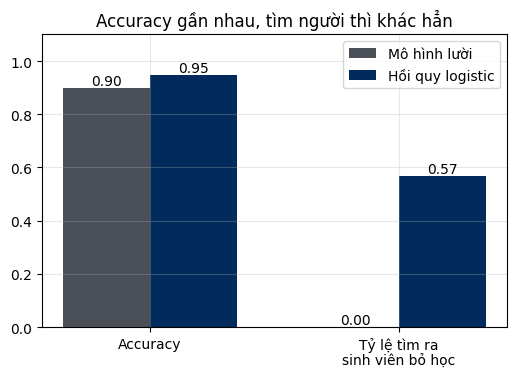

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
print("Kích thước bảng:", df.shape)
display(df.head())
print("\nSố sinh viên mỗi lớp:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Tỷ lệ bỏ học: {df['bo_hoc'].mean():.3f}\n")

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
# stratify=y giữ đúng tỷ lệ bỏ học ở cả tập học lẫn tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
print(f"Tập kiểm tra: {len(y_te)} bạn, {y_te.sum()} bạn bỏ học\n")

# Mô hình lười: ai cũng đoán là lớp đông nhất
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)
lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

ket_qua = {}
for ten, du in [("Mô hình lười", du_luoi), ("Hồi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = int(((du == 1) & (y_te == 1)).sum())
    ket_qua[ten] = (acc, tim_ra / y_te.sum())
    print(f"{ten:17s} accuracy {acc:.4f}, tìm ra {tim_ra} trên {y_te.sum()} bạn bỏ học")

# Hình 1
fig, ax = plt.subplots(figsize=(6, 3.8))
w = 0.35
nhan = ["Accuracy", "Tỷ lệ tìm ra\nsinh viên bỏ học"]
for i, (ten, mau) in enumerate([("Mô hình lười", "#4b5058"), ("Hồi quy logistic", "#002b5c")]):
    v = ket_qua[ten]
    b = ax.bar(np.arange(2) + (i - 0.5) * w, v, w, label=ten, color=mau)
    ax.bar_label(b, fmt="%.2f")
ax.set_xticks(range(2)); ax.set_xticklabels(nhan); ax.set_ylim(0, 1.1)
ax.set_title("Accuracy gần nhau, tìm người thì khác hẳn"); ax.legend()
plt.show()

## 3. Ma trận nhầm lẫn

Tự đếm:
  TP = 17  (đoán bỏ học, đúng là bỏ học)
  FP = 3  (báo động nhầm)
  FN = 13  (bỏ sót)
  TN = 267  (đoán không bỏ, đúng là không bỏ)
  Tổng = 300

confusion_matrix của scikit-learn:
[[267   3]
 [ 13  17]]
Thứ tự khi trải ra: TN, FP, FN, TP = [267   3  13  17] 

Accuracy tính từ bốn ô: (17 + 267) / 300 = 0.9467
Số bạn bị báo có nguy cơ: TP + FP = 20


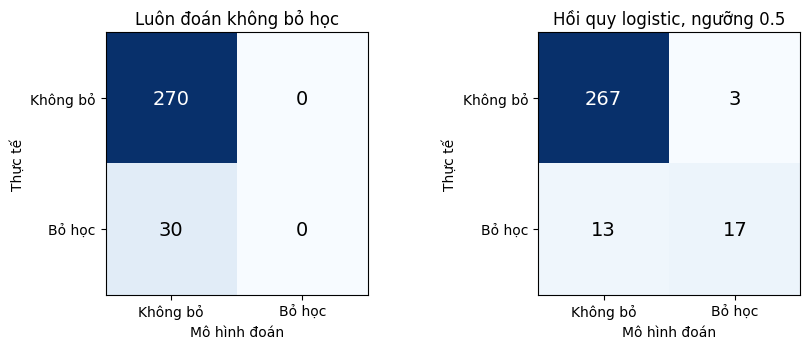

In [3]:
from sklearn.metrics import confusion_matrix

du = lr.predict(X_te)
that = y_te.to_numpy()

# Tự đếm: mỗi ô là một cặp (nhãn thật, nhãn đoán)
tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))
print("Tự đếm:")
print(f"  TP = {tp}  (đoán bỏ học, đúng là bỏ học)")
print(f"  FP = {fp}  (báo động nhầm)")
print(f"  FN = {fn}  (bỏ sót)")
print(f"  TN = {tn}  (đoán không bỏ, đúng là không bỏ)")
print(f"  Tổng = {tp + fp + fn + tn}\n")

m = confusion_matrix(that, du)
print("confusion_matrix của scikit-learn:")
print(m)
print("Thứ tự khi trải ra: TN, FP, FN, TP =", m.ravel(), "\n")
acc = (tp + tn) / (tp + fp + fn + tn)
print(f"Accuracy tính từ bốn ô: ({tp} + {tn}) / {len(that)} = {acc:.4f}")
print(f"Số bạn bị báo có nguy cơ: TP + FP = {tp + fp}")

# Hình 2: ma trận của mô hình lười và của logistic
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (ten, d) in zip(axs, [("Luôn đoán không bỏ học", du_luoi), ("Hồi quy logistic, ngưỡng 0.5", du_lr)]):
    cm = confusion_matrix(that, d, labels=[0, 1])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Không bỏ", "Bỏ học"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Không bỏ", "Bỏ học"])
    ax.set_xlabel("Mô hình đoán"); ax.set_ylabel("Thực tế"); ax.set_title(ten)
plt.tight_layout(); plt.show()

## 4. Precision, recall và F1

In [4]:
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score

tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()
p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tính tay từ bốn ô:")
print(f"  Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f"  Recall    = {tp} / ({tp} + {fn}) = {r:.4f}")
print(f"  F1        = 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f}) = {f1:.4f}\n")

print("Tính bằng scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall    = {recall_score(y_te, du):.4f}")
print(f"  F1        = {f1_score(y_te, du):.4f}\n")

print("Báo cáo đầy đủ:")
print(classification_report(y_te, du, digits=4, target_names=["không bỏ", "bỏ học"]))

Tính tay từ bốn ô:
  Precision = 17 / (17 + 3) = 0.8500
  Recall    = 17 / (17 + 13) = 0.5667
  F1        = 2 x 0.8500 x 0.5667 / (0.8500 + 0.5667) = 0.6800

Tính bằng scikit-learn:
  Precision = 0.8500
  Recall    = 0.5667
  F1        = 0.6800

Báo cáo đầy đủ:
              precision    recall  f1-score   support

    không bỏ     0.9536    0.9889    0.9709       270
      bỏ học     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



## 5. Đổi ngưỡng quyết định

Tập kiểm tra, đổi ngưỡng
ngưỡng  số báo  TP  FP  FN  precision  recall      F1
  0.5      20   17   3  13   0.8500   0.5667  0.6800
  0.4      21   18   3  12   0.8571   0.6000  0.7059
  0.3      29   21   8   9   0.7241   0.7000  0.7119
  0.2      42   24  18   6   0.5714   0.8000  0.6667
  0.1      61   26  35   4   0.4262   0.8667  0.5714

Ngưỡng cho F1 cao nhất trên tập học: 0.25 (F1 kiểm định chéo 0.6473)
Tập kiểm tra với ngưỡng 0.25: precision 0.6571, recall 0.7667, F1 0.7077


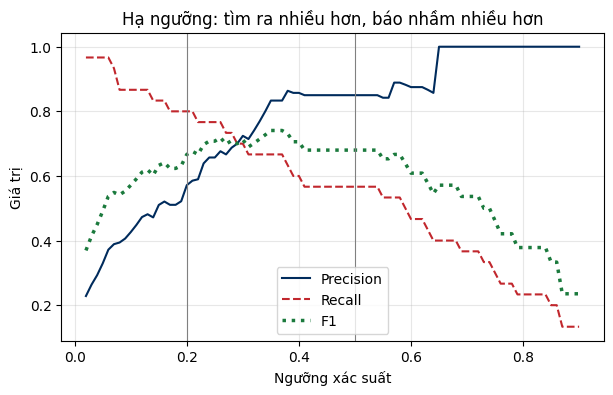

In [5]:
from sklearn.model_selection import cross_val_predict

xs = lr.predict_proba(X_te)[:, 1]   # xác suất bỏ học của từng bạn

print("Tập kiểm tra, đổi ngưỡng")
print("ngưỡng  số báo  TP  FP  FN  precision  recall      F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    d = (xs >= t).astype(int)
    tp_ = int(((d == 1) & (y_te == 1)).sum())
    fp_ = int(((d == 1) & (y_te == 0)).sum())
    fn_ = int(((d == 0) & (y_te == 1)).sum())
    print(f"  {t:.1f}   {d.sum():5d}  {tp_:3d} {fp_:3d} {fn_:3d}   "
          f"{precision_score(y_te, d, zero_division=0):.4f}   {recall_score(y_te, d):.4f}  {f1_score(y_te, d):.4f}")
print()

# Chọn ngưỡng đúng cách: chỉ dùng tập học, qua kiểm định chéo.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Ngưỡng cho F1 cao nhất trên tập học: {t_tot} (F1 kiểm định chéo {max(f1_hoc):.4f})")

# Chọn xong mới dùng tập kiểm tra, và chỉ một lần
d = (xs >= t_tot).astype(int)
print(f"Tập kiểm tra với ngưỡng {t_tot}: precision {precision_score(y_te, d):.4f}, "
      f"recall {recall_score(y_te, d):.4f}, F1 {f1_score(y_te, d):.4f}")

# Hình 3
ng = np.arange(0.02, 0.91, 0.01)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ng, [precision_score(y_te, (xs >= t).astype(int), zero_division=0) for t in ng], label="Precision", color="#002b5c")
ax.plot(ng, [recall_score(y_te, (xs >= t).astype(int)) for t in ng], "--", label="Recall", color="#c1272d")
ax.plot(ng, [f1_score(y_te, (xs >= t).astype(int)) for t in ng], ":", lw=2.5, label="F1", color="#1b7a3d")
for t in (0.2, 0.5): ax.axvline(t, color="gray", lw=0.8)
ax.set_xlabel("Ngưỡng xác suất"); ax.set_ylabel("Giá trị"); ax.legend()
ax.set_title("Hạ ngưỡng: tìm ra nhiều hơn, báo nhầm nhiều hơn")
plt.show()

## 6. Đường ROC và AUC

Đường ROC có 28 điểm. Vài điểm đầu:
  báo động nhầm   recall
     0.0000       0.0000
     0.0000       0.0333
     0.0000       0.4000
     0.0074       0.4000
     0.0074       0.5333
     0.0111       0.5333
AUC của logistic = 0.9449

Mô hình          AUC     recall  F1 (ngưỡng 0.5)
  Logistic       0.9449  0.5667  0.6800
  Naive Bayes    0.9336  0.3667  0.5116
  KNN, k = 15    0.9274  0.2333  0.3684
  Cây sâu 4      0.8803  0.4667  0.5957
  Rừng 200 cây   0.9249  0.5667  0.6538
  SVM RBF        0.8996  0.5000  0.6250


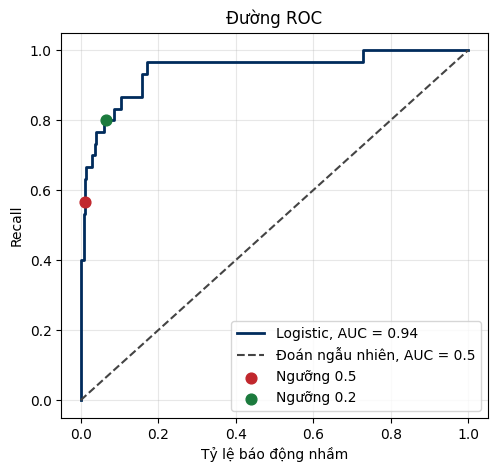

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

xs = lr.predict_proba(X_te)[:, 1]
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Đường ROC có", len(fpr), "điểm. Vài điểm đầu:")
print("  báo động nhầm   recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"     {a:.4f}       {b:.4f}")
print(f"AUC của logistic = {roc_auc_score(y_te, xs):.4f}\n")

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "Cây sâu 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rừng 200 cây": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)),
}
print("Mô hình          AUC     recall  F1 (ngưỡng 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    pr = mh.predict_proba(X_te)[:, 1]
    d = (pr >= 0.5).astype(int)
    print(f"  {ten:14s} {roc_auc_score(y_te, pr):.4f}  {recall_score(y_te, d):.4f}  {f1_score(y_te, d):.4f}")

# Hình 4
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#002b5c", lw=2, label=f"Logistic, AUC = {roc_auc_score(y_te, xs):.2f}")
ax.plot([0, 1], [0, 1], "--", color="#444", label="Đoán ngẫu nhiên, AUC = 0.5")
for t, mau in [(0.5, "#c1272d"), (0.2, "#1b7a3d")]:
    d = (xs >= t).astype(int)
    f_ = ((d == 1) & (y_te == 0)).sum() / (y_te == 0).sum()
    ax.scatter(f_, recall_score(y_te, d), s=60, color=mau, zorder=5, label=f"Ngưỡng {t}")
ax.set_xlabel("Tỷ lệ báo động nhầm"); ax.set_ylabel("Recall"); ax.set_title("Đường ROC"); ax.legend(loc="lower right")
plt.show()

## 7. Kiểm định chéo nhiều thước đo và cân bằng lớp

In [7]:
from sklearn.model_selection import cross_val_score

# Chia không phân tầng: số bạn bỏ học trong tập kiểm tra dao động
print("Không stratify, số bạn bỏ học trong tập kiểm tra:")
dem = []
for rs in range(10):
    _, _, _, y_te_thu = train_test_split(X, y, test_size=0.25, random_state=rs)
    dem.append(int(y_te_thu.sum()))
print(" ", dem, "\n")

print("Kiểm định chéo 5 phần trên tập học:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d_ = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f"  {tm:10s} {d_.mean():.4f}")
print()

# Cân bằng lớp: phạt nặng hơn khi đoán sai lớp hiếm
cb = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
print("Tập kiểm tra     precision  recall      F1")
for ten, mh in [("Bình thường", lr), ("Cân bằng lớp", cb)]:
    d = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"  {ten:12s}   {precision_score(y_te, d):.4f}   {recall_score(y_te, d):.4f}  {f1_score(y_te, d):.4f}")

Không stratify, số bạn bỏ học trong tập kiểm tra:
  [22, 26, 35, 29, 32, 27, 28, 20, 27, 23] 

Kiểm định chéo 5 phần trên tập học:
  accuracy   0.9289
  precision  0.7044
  recall     0.4810
  f1         0.5652

Tập kiểm tra     precision  recall      F1
  Bình thường    0.8500   0.5667  0.6800
  Cân bằng lớp   0.4483   0.8667  0.5909


## 8. Bài tập


### Bài tập 1: Tự viết hàm đánh giá (chỉ dùng numpy)

In [8]:
def danh_gia(y_that, y_doan):
    """Trả về accuracy, precision, recall, F1. Chia cho 0 thì trả 0.0 (giống zero_division=0)."""
    y_that = np.asarray(y_that); y_doan = np.asarray(y_doan)
    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))
    acc = (tp + tn) / len(y_that)
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    return acc, p, r, f1

lr.fit(X_tr, y_tr)
for ten, d in [("Logistic", lr.predict(X_te)), ("Mô hình lười", luoi.predict(X_te))]:
    tu_viet = danh_gia(y_te, d)
    thu_vien = (accuracy_score(y_te, d), precision_score(y_te, d, zero_division=0),
                recall_score(y_te, d), f1_score(y_te, d, zero_division=0))
    print(ten)
    print("  hàm tự viết :", np.round(tu_viet, 4))
    print("  scikit-learn:", np.round(thu_vien, 4))
    print("  khớp nhau   :", np.allclose(tu_viet, thu_vien))

Logistic
  hàm tự viết : [0.9467 0.85   0.5667 0.68  ]
  scikit-learn: [0.9467 0.85   0.5667 0.68  ]
  khớp nhau   : True
Mô hình lười
  hàm tự viết : [0.9 0.  0.  0. ]
  scikit-learn: [0.9 0.  0.  0. ]
  khớp nhau   : True


### Bài tập 2: Chữ số viết tay (SVM của bài 6)

In [9]:
from sklearn.datasets import load_digits

Xd, yd = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25, random_state=17, stratify=yd)
svm = SVC().fit(Xd_tr, yd_tr)
dd = svm.predict(Xd_te)
print(classification_report(yd_te, dd, digits=4))

p_ = precision_score(yd_te, dd, average=None)
r_ = recall_score(yd_te, dd, average=None)
print(f"Chữ số recall thấp nhất   : {r_.argmin()} (recall {r_.min():.4f})")
print(f"Chữ số precision thấp nhất: {p_.argmin()} (precision {p_.min():.4f})")
print("Số mẫu mỗi chữ số trong tập kiểm tra:", np.bincount(yd_te))

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Chữ số recall thấp nhất   : 8 (recall 0.9767)
Chữ số precision thấp nhất: 8 (precision 0.9767)
Số mẫu mỗi chữ số trong tập kiểm tra: [45 46 44 46 45 46 45 45 43 45]


### Bài tập 3: Chọn ngưỡng theo yêu cầu (recall ≥ 0.8)

In [10]:
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
luoi_nguong = np.round(np.arange(0.01, 0.96, 0.01), 2)
recall_hoc = np.array([recall_score(y_tr, (xs_hoc >= t).astype(int)) for t in luoi_nguong])
du_dk = luoi_nguong[recall_hoc >= 0.8]
t_chon = du_dk.max()   # ngưỡng LỚN NHẤT mà recall (kiểm định chéo) vẫn >= 0.8
print(f"Ngưỡng lớn nhất cho recall CV >= 0.8: {t_chon} (recall CV = {recall_hoc[luoi_nguong == t_chon][0]:.4f})")

xs_te = lr.predict_proba(X_te)[:, 1]
d = (xs_te >= t_chon).astype(int)       # áp lên tập kiểm tra đúng một lần
print(f"Tập kiểm tra: recall {recall_score(y_te, d):.4f}, precision {precision_score(y_te, d):.4f}, "
      f"số bạn bị báo {d.sum()} / {len(d)}")
print("Recall có đạt 0.8 không?", "CÓ" if recall_score(y_te, d) >= 0.8 else "KHÔNG")

Ngưỡng lớn nhất cho recall CV >= 0.8: 0.17 (recall CV = 0.8090)
Tập kiểm tra: recall 0.8000, precision 0.5106, số bạn bị báo 47 / 300
Recall có đạt 0.8 không? CÓ


### Bài tập 4: Tự vẽ đường ROC (logistic và rừng ngẫu nhiên)

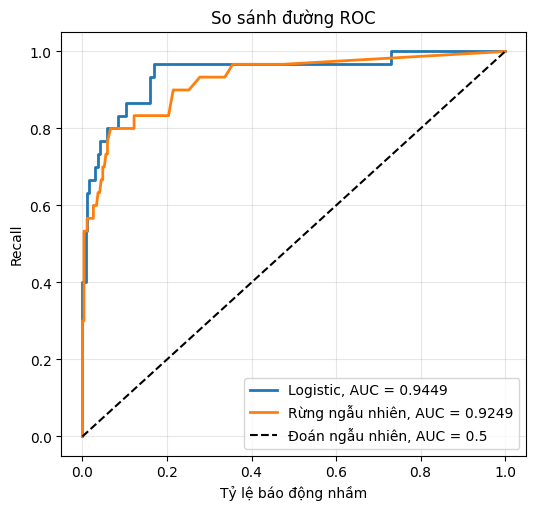

Đường ôm sát góc trên-trái hơn (AUC lớn hơn): Logistic
Số lần hai đường cắt nhau: 2 | tại tỷ lệ báo động nhầm ≈ [0.003 0.729]


In [11]:
rf = RandomForestClassifier(200, random_state=0).fit(X_tr, y_tr)
p_lr = lr.predict_proba(X_te)[:, 1]
p_rf = rf.predict_proba(X_te)[:, 1]
f1_, t1_, _ = roc_curve(y_te, p_lr)
f2_, t2_, _ = roc_curve(y_te, p_rf)
auc1, auc2 = roc_auc_score(y_te, p_lr), roc_auc_score(y_te, p_rf)

plt.figure(figsize=(6, 5.5))
plt.plot(f1_, t1_, lw=2, label=f"Logistic, AUC = {auc1:.4f}")
plt.plot(f2_, t2_, lw=2, label=f"Rừng ngẫu nhiên, AUC = {auc2:.4f}")
plt.plot([0, 1], [0, 1], "k--", label="Đoán ngẫu nhiên, AUC = 0.5")
plt.xlabel("Tỷ lệ báo động nhầm"); plt.ylabel("Recall"); plt.title("So sánh đường ROC"); plt.legend(loc="lower right")
plt.savefig("roc.png", dpi=150, bbox_inches="tight"); plt.show()

# Kiểm tra hai đường có cắt nhau không (nội suy trên cùng lưới hoành độ)
luoi = np.linspace(0, 1, 1001)
chenh = np.interp(luoi, f1_, t1_) - np.interp(luoi, f2_, t2_)
doi_dau = np.where(chenh[:-1] * chenh[1:] < 0)[0]
print("Đường ôm sát góc trên-trái hơn (AUC lớn hơn):", "Logistic" if auc1 > auc2 else "Rừng ngẫu nhiên")
print("Số lần hai đường cắt nhau:", len(doi_dau),
      "| tại tỷ lệ báo động nhầm ≈", np.round(luoi[doi_dau], 3))

### Bài tập 5: Cân bằng lớp cho rừng ngẫu nhiên và SVC

In [12]:
def chi_so(mh):
    d = mh.fit(X_tr, y_tr).predict(X_te)
    return precision_score(y_te, d, zero_division=0), recall_score(y_te, d), f1_score(y_te, d)

cac = {
    "Rừng ngẫu nhiên": (RandomForestClassifier(200, random_state=0),
                        RandomForestClassifier(200, class_weight="balanced", random_state=0)),
    "SVC (RBF)": (make_pipeline(StandardScaler(), SVC(random_state=0)),
                  make_pipeline(StandardScaler(), SVC(class_weight="balanced", random_state=0))),
}
hang = []
for ten, (truoc, sau) in cac.items():
    a, b = chi_so(truoc), chi_so(sau)
    hang.append([ten, "trước", *a]); hang.append([ten, "sau", *b])
    hang.append([ten, "thay đổi", *(np.array(b) - np.array(a))])
bang = pd.DataFrame(hang, columns=["Mô hình", "Giai đoạn", "Precision", "Recall", "F1"]).round(4)
display(bang)
dr = {ten: abs(chi_so(s)[1] - chi_so(t)[1]) for ten, (t, s) in cac.items()}
print("Mô hình thay đổi recall nhiều nhất:", max(dr, key=dr.get), dr)

,Mô hình,Giai đoạn,Precision,Recall,F1
0,Rừng ngẫu nhiên,trước,0.7727,0.5667,0.6538
1,Rừng ngẫu nhiên,sau,0.7500,0.4000,0.5217
2,Rừng ngẫu nhiên,thay đổi,-0.0227,-0.1667,-0.1321
3,SVC (RBF),trước,0.8824,0.5000,0.6383
4,SVC (RBF),sau,0.4464,0.8333,0.5814
5,SVC (RBF),thay đổi,-0.4359,0.3333,-0.0569


Mô hình thay đổi recall nhiều nhất: SVC (RBF) {'Rừng ngẫu nhiên': 0.16666666666666663, 'SVC (RBF)': 0.33333333333333337}


### Bài tập 6: MAE và RMSE với một lần đoán hỏng (giá nhà, bài 1)

In [13]:
def doc_du_lieu_gia_nha():
    """Tìm tệp giá nhà của bài 1 trong data/. Nếu tự động đoán sai cột, sửa 3 biến CẤU HÌNH bên dưới."""
    TEP = None        # CẤU HÌNH: ví dụ "data/gia_nha.csv"
    COT_GIA = None    # CẤU HÌNH: tên cột giá nhà
    COT_DIEN_TICH = None  # CẤU HÌNH: tên cột diện tích (m2)
    if TEP is None:
        ds = glob.glob("data/*.csv")
        uu_tien = [f for f in ds if any(k in os.path.basename(f).lower() for k in ["nha", "house", "price"])]
        if not uu_tien:
            raise FileNotFoundError("Không tìm thấy tệp giá nhà trong data/, hãy điền biến TEP.")
        TEP = sorted(uu_tien)[0]
    d = pd.read_csv(TEP).select_dtypes("number").dropna()
    if COT_GIA is None:
        ung = [c for c in d.columns if any(k in c.lower() for k in ["gia", "price"])]
        COT_GIA = ung[0] if ung else d.columns[-1]
    if COT_DIEN_TICH is None:
        ung = [c for c in d.columns if c != COT_GIA and any(k in c.lower() for k in ["dien_tich", "dt", "m2", "area"])]
        COT_DIEN_TICH = ung[0] if ung else [c for c in d.columns if c != COT_GIA][0]
    print(f"Tệp: {TEP} | cột giá: {COT_GIA} | cột diện tích: {COT_DIEN_TICH} | cột đặc trưng: {[c for c in d.columns if c != COT_GIA]}")
    return d.drop(columns=COT_GIA), d[COT_GIA], COT_DIEN_TICH

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xn, yn, cot_dt = doc_du_lieu_gia_nha()
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.25, random_state=17)
hq = LinearRegression().fit(Xn_tr, yn_tr)
dn = hq.predict(Xn_te)

# 5 tỷ đồng: đổi theo đơn vị của cột giá (tỷ -> 5, triệu -> 5000, đồng -> 5e9)
trung_vi = float(np.median(yn))
THEM = 5 if trung_vi < 1000 else (5000 if trung_vi < 1e6 else 5e9)
print(f"Trung vị giá = {trung_vi:,.2f} -> cộng thêm {THEM:,} vào dự đoán của đúng một căn\n")

def ba_so(y_that, y_doan):
    return (mean_absolute_error(y_that, y_doan),
            np.sqrt(mean_squared_error(y_that, y_doan)),
            r2_score(y_that, y_doan))

dn_hong = dn.copy(); dn_hong[0] += THEM
truoc, sau = ba_so(yn_te, dn), ba_so(yn_te, dn_hong)
bang = pd.DataFrame({"Trước": truoc, "Sau": sau}, index=["MAE", "RMSE", "R2"])
bang["Tăng (lần)"] = bang["Sau"] / bang["Trước"]
display(bang.round(4))
print("Số thay đổi tương đối lớn nhất:", (bang["Sau"] / bang["Trước"] - 1).abs().idxmax())

Tệp: data/gia_nha.csv | cột giá: gia | cột diện tích: dien_tich | cột đặc trưng: ['dien_tich', 'so_phong', 'tuoi_nha']
Trung vị giá = 6.40 -> cộng thêm 5 vào dự đoán của đúng một căn



,Trước,Sau,Tăng (lần)
MAE,0.2185,0.5519,2.5252
RMSE,0.2700,1.4433,5.3451
R2,0.9759,0.3110,0.3187


Số thay đổi tương đối lớn nhất: RMSE
